# 1. Data audit: what is really in this table?

The data is the Pima Indians Diabetes dataset: 768 women aged 21 and over, of Pima heritage, examined near Phoenix, Arizona by the National Institute of Diabetes and Digestive and Kidney Diseases. Each row has eight measurements and whether the woman was diagnosed with diabetes within five years.

Before any modeling, this notebook checks whether the numbers can be trusted as written. They can't, and that shapes everything after it.

In [1]:
import sys, warnings
sys.path.insert(0, "..")          # so the notebook can import the project's src/ folder
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

## 1.1 First look

**What we're looking for.** The size of the table and any values that are impossible for a living person.

In [2]:
from src.data import load_raw
raw = load_raw()
print(raw.shape)
raw.describe().T[["min", "50%", "max"]]

(768, 9)


,min,50%,max
Pregnancies,0.000,3.000,17.000
Glucose,0.000,117.000,199.000
BloodPressure,0.000,72.000,122.000
SkinThickness,0.000,23.000,99.000
Insulin,0.000,30.500,846.000
BMI,0.000,32.000,67.100
DiabetesPedigreeFunction,0.078,0.372,2.420
Age,21.000,29.000,81.000
Outcome,0.000,0.000,1.000


**How to read it.** Each row is one measurement. `min` is the smallest value recorded, `50%` is the middle value (the median) and `max` is the largest.

**What it means.** Five measurements have a minimum of 0: glucose, blood pressure, skinfold thickness, insulin and BMI. Nobody has a blood pressure or a BMI of zero. The file has no blank cells, so a zero was used to mean "not recorded".

**What's next and why.** Count how many of these hidden gaps there are, because the answer decides how much we can lean on each column.

## 1.2 How much is missing

**What we're looking for.** The number of impossible zeros in each column.

,missing,percent
Insulin,374,48.700
SkinThickness,227,29.600
BloodPressure,35,4.600
BMI,11,1.400
Glucose,5,0.700
Pregnancies,0,0.000
DiabetesPedigreeFunction,0,0.000
Age,0,0.000


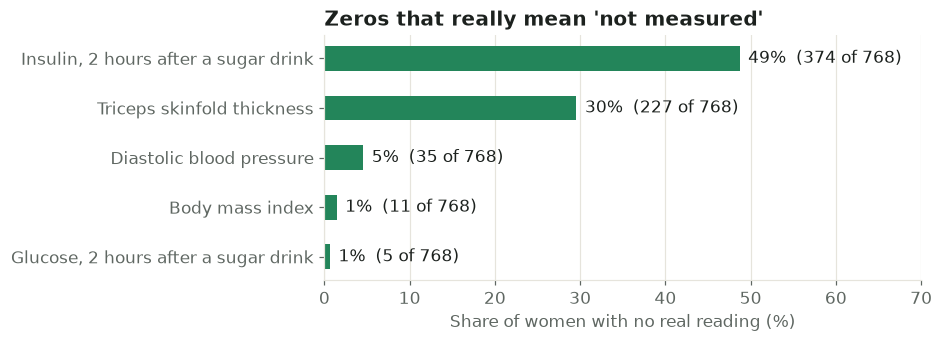

In [3]:
from src.data import missing_summary
from src import figures
display(missing_summary())
figures.missing_values();

**How to read it.** Each bar is one measurement. Its length is the share of the 768 women who have a zero where a real reading should be.

**What it means.** Insulin is missing for 374 women (49%) and skinfold thickness for 227 (30%). The other three columns are missing for 5% or fewer. The original college notebook filled these with a single typical value worked out from the whole table. For insulin that means half the column was invented, and the fill value itself was pulled down by the zeros it was meant to replace.

**What's next and why.** From here on, `load_data()` turns those zeros into proper missing values. Filling them in happens later, inside the model pipeline, so it is learned from training rows only.

## 1.3 Is a missing reading itself a clue?

**What we're looking for.** Whether women with no insulin or skinfold reading were diagnosed more or less often. If they were, the gap carries information and should not be papered over.

In [4]:
from src.data import load_data
X, y = load_data()
pd.DataFrame({
    "diabetes rate when recorded": [y[X[c].notna()].mean() for c in ["Insulin", "SkinThickness"]],
    "diabetes rate when missing":  [y[X[c].isna()].mean()  for c in ["Insulin", "SkinThickness"]],
}, index=["Insulin", "SkinThickness"])

,diabetes rate when recorded,diabetes rate when missing
Insulin,0.330,0.369
SkinThickness,0.333,0.388


**How to read it.** Each row compares two groups of women: those with a real reading and those without. The numbers are the share diagnosed with diabetes (0.33 = 33%).

**What it means.** The rates are close: 33% against 37% for insulin, 33% against 39% for skinfold. Missing readings lean slightly toward diabetes, but not enough to be a strong signal on their own.

**What's next and why.** Milestone 2 tests this properly by comparing several ways of handling the gaps (E08).

## 1.4 How common is diabetes here?

**What we're looking for.** The share of women diagnosed. That number is the score a model gets for doing nothing.

In [5]:
print(y.value_counts().rename({0: "no diabetes", 1: "diabetes"}))
print(f"\nShare with diabetes: {y.mean():.1%}")
print(f"Accuracy from always answering 'no diabetes': {1 - y.mean():.1%}")

Outcome
no diabetes    500
diabetes       268
Name: count, dtype: int64

Share with diabetes: 34.9%
Accuracy from always answering 'no diabetes': 65.1%


**How to read it.** The counts are women in each group. The last line is the accuracy of a "model" that never predicts diabetes for anyone.

**What it means.** 268 of 768 women (35%) were diagnosed. Always answering "no" is right 65% of the time while catching nobody. So 65% is the floor, and accuracy alone is a poor yardstick: a model can look decent while missing most of the people it exists to find.

**What's next and why.** Later notebooks report how many true cases are caught (sensitivity) alongside accuracy.

## 1.5 Which measurements differ between the two groups?

**What we're looking for.** A quick, honest read of direction: for each measurement, is the typical value higher or lower among women who were diagnosed?

In [6]:
med = X.groupby(y).median().T
med.columns = ["no diabetes", "diabetes"]
med["difference"] = med["diabetes"] - med["no diabetes"]
med

,no diabetes,diabetes,difference
Pregnancies,2.000,4.000,2.000
Glucose,107.000,140.000,33.000
BloodPressure,70.000,74.500,4.500
SkinThickness,27.000,32.000,5.000
Insulin,102.500,169.500,67.000
BMI,30.100,34.300,4.200
DiabetesPedigreeFunction,0.336,0.449,0.113
Age,27.000,36.000,9.000


**How to read it.** Each row is a measurement. The two columns are the median for each group, using real readings only.

**What it means.** Every measurement is higher in the diabetes group. Glucose shows the largest gap (140 against 107), followed by insulin, age (36 against 27) and BMI. The original notebook said glucose, insulin, family history and pregnancies were *lower* among women with diabetes. That was a misreading of a crowded chart (B07).

**What's next and why.** Notebook 2 turns to modeling, starting with why the original 81% accuracy can't be taken at face value.